In [1]:
import os
import sys
import numpy as np

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

from rect_prune_ood.lib.util.paths import get_top_level_path

results_dir = os.path.join(get_top_level_path(), 'results')
imagenet_c_results_dir = os.path.join(results_dir, 'imagenet', "baseline", "imagenet_c")
ablation_study_results_dir = os.path.join(results_dir, 'ablation_study_pertubation')
os.makedirs(ablation_study_results_dir, exist_ok=True)

imagenet_c_pertubations = [
        "gaussian_noise", 
        "saturate",
        "brightness",
        "pixelate",
        "snow",
        "motion_blur",
        "elastic_transform",
        "fog",
        "zoom_blur",
        "shot_noise",
        "contrast",
        "defocus_blur",
        "frost",
        "impulse_noise",
        "jpeg_compression",
        "glass_blur",
    ]

imagenet_c_pertubations_file = [
        "brightness",
        "defocus_blur",
        "fog",
        "gaussian_blur",
        "glass_blur",
        "jpeg_compression",
        "pixelate",
        "shot_noise",
        "spatter",
        "zoom_blur",
        "contrast",
        "elastic_transform",
        "frost",
        "gaussian_noise", 
        "impulse_noise",
        "motion_blur",
        "saturate",
        "snow",
        "speckle_noise"
    ]

In [2]:
from torch.nn import Module
from torch import Tensor


class APESP(Module):
    def __init__(self, mask) -> None:
        #super(LayerScaler, self).__init__()
        super(APESP, self).__init__()
        self.mask = mask
        
    
    def forward(self, x: Tensor) -> Tensor:
        x = self.apes_p(x)
        return x
    
    def apes_p(self, x):
        assert x.dim() == 4
        _, c, _, _ = x.shape
        assert self.mask.shape[0] == c 

        x = x * self.mask

        return x

In [3]:
imagenet_c_activations = np.load(os.path.join(imagenet_c_results_dir, "imagenet_c_activations_severity_5.npy"))
imagenet_activations = np.load(os.path.join(results_dir, 'imagenet', 'baseline', 'imagenet_activations.npy'))
print(imagenet_c_activations.shape)
print(imagenet_activations.shape)
imagenet_activations = np.transpose(imagenet_activations)
print(imagenet_activations.shape)

(19, 2048, 50000)
(50000, 2048)
(2048, 50000)


In [13]:
import torch
from lightning import Trainer
from rect_prune_ood.lib.experiments.feature_extractor import FeatureExtractor
from rect_prune_ood.lib.experiments.backbones import get_resnet50
from rect_prune_ood.lib.experiments.pipeline import Pipeline
from rect_prune_ood.lib.util.data_loader import get_data_loader

masks = []

for i in range(len(imagenet_c_pertubations)):

    # if i == 1:
    #     break

    pertubation_index = []
    for j in range(i + 1):
        pertubation_index.append(imagenet_c_pertubations_file.index(imagenet_c_pertubations[j]))

    # concatenate the activations. data has shape (19, 2048, 50000), goal is to get (2048, x) 
    activations = np.concatenate([imagenet_c_activations[j] for j in pertubation_index], axis=1)

    #activations = imagenet_c_activations[imagenet_c_pertubations_file.index(imagenet_c_pertubations[i])]
    # concatenate with imagenet activations
    #activations = np.concatenate([activations, imagenet_activations], axis=1)

    variance = np.var(activations, axis=1)
    variance = torch.tensor(variance)

    percentile = np.percentile(variance, 95)

    mask = torch.where(variance <= percentile, 1, 0)
    mask = mask.view(variance.shape[0], 1, 1).cuda()


    #################
    ### ImageNet ####
    #################
    
    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('imagenet', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_pertubations_imagenet_{i+1}.npy"), results)

    ####################
    ### OpenImage-O ####
    ####################

    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('openimage-o', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_pertubations_openimage-o_{i+1}.npy"), results)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

... (54 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

In [8]:
import torch
from lightning import Trainer
from rect_prune_ood.lib.experiments.feature_extractor import FeatureExtractor
from rect_prune_ood.lib.experiments.backbones import get_resnet50
from rect_prune_ood.lib.experiments.pipeline import Pipeline
from rect_prune_ood.lib.util.data_loader import get_data_loader

pertubation_index = []
for j in range(4):
    pertubation_index.append(imagenet_c_pertubations_file.index(imagenet_c_pertubations[j]))

activations = np.concatenate([imagenet_c_activations[j] for j in pertubation_index], axis=1)

variance = np.var(activations, axis=1)
variance = torch.tensor(variance)

for p in [35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]:
    percentile = np.percentile(variance, p)

    mask = torch.where(variance <= percentile, 1, 0)
    mask = mask.view(variance.shape[0], 1, 1).cuda()


    #################
    ### ImageNet ####
    #################

    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')

    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('imagenet', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_imagenet_pruning_percentile_{p}.npy"), results)

    ####################
    ### OpenImage-O ####
    ####################

    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')

    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('openimage-o', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_openimage-o_pruning_percentile_{p}.npy"), results)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

... (46 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

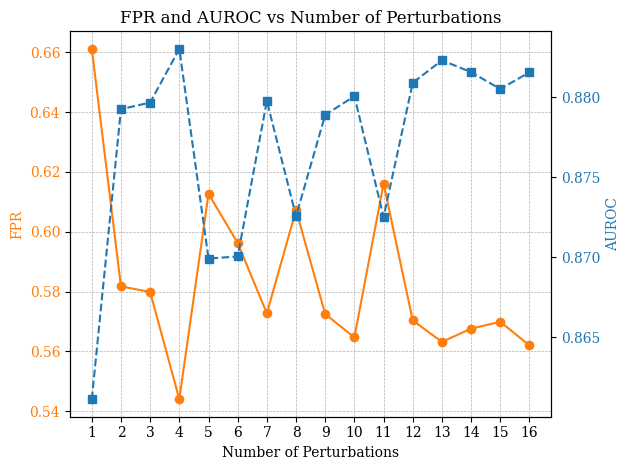

In [40]:
import matplotlib.pyplot as plt

from rect_prune_ood.lib.eval.metrics import *

#openimage_o_scores = np.load(os.path.join(results_dir, 'imagenet', 'apesp@95', 'openimage-o.npy'), allow_pickle=True).item()["energy_score"]

all_results = []

for i in range(len(imagenet_c_pertubations)):

    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_imagenet_{i+1}.npy"), allow_pickle=True).item()["energy_score"]
    openimage_o_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_openimage-o_{i+1}.npy"), allow_pickle=True).item()["energy_score"]

    results = cal_metric(imagenet_scores, openimage_o_scores)
    results["num_pertubations"] = i + 1

    all_results.append(results)

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Plot results
num_perturbations = [res["num_pertubations"] for res in all_results]
fpr_values = [res["FPR"] for res in all_results]
auroc_values = [res["AUROC"] for res in all_results]

fig, ax1 = plt.subplots()

# Left y-axis for FPR
ax1.set_xlabel("Number of Perturbations")
ax1.set_ylabel("FPR", color="tab:orange")
ax1.plot(num_perturbations, fpr_values, marker='o', linestyle='-', color="tab:orange", label="FPR")
ax1.tick_params(axis='y', labelcolor="tab:orange")
ax1.set_xticks(num_perturbations)  # Show all perturbation values on x-axis
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Right y-axis for AUROC
ax2 = ax1.twinx()
ax2.set_ylabel("AUROC", color="tab:blue")
ax2.plot(num_perturbations, auroc_values, marker='s', linestyle='--', color="tab:blue", label="AUROC")
ax2.tick_params(axis='y', labelcolor="tab:blue")

plt.title("FPR and AUROC vs Number of Perturbations")
fig.tight_layout()
pdf_path = os.path.join(ablation_study_results_dir, "num_perturbations_fpr_auroc_plot.pdf")
plt.savefig(pdf_path, format="pdf")
plt.show()

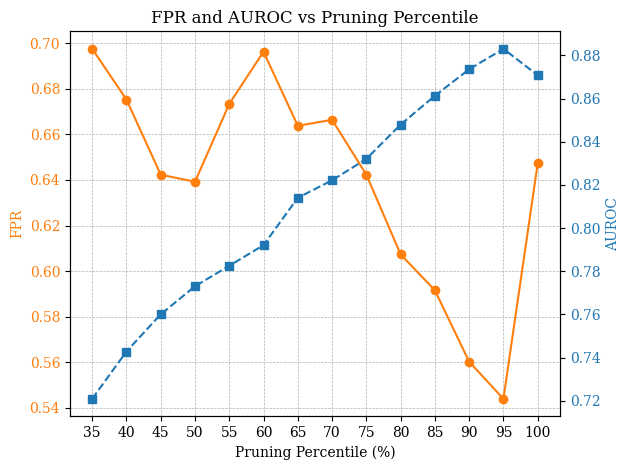

In [43]:
import matplotlib.pyplot as plt

from rect_prune_ood.lib.eval.metrics import *

all_results = []

for p in [35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]:
    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"as_imagenet_pruning_percentile_{p}.npy"), allow_pickle=True).item()["energy_score"]
    openimage_o_scores = np.load(os.path.join(ablation_study_results_dir, f"as_openimage-o_pruning_percentile_{p}.npy"), allow_pickle=True).item()["energy_score"]

    results = cal_metric(imagenet_scores, openimage_o_scores)
    results["percentile"] = p

    all_results.append(results)

plt.rcParams.update({
    "font.family": "serif"
})

# Plot results
percentiles = [res["percentile"] for res in all_results]
fpr_values = [res["FPR"] for res in all_results]
auroc_values = [res["AUROC"] for res in all_results]

fig, ax1 = plt.subplots()

# Left y-axis for FPR
ax1.set_xlabel("Pruning Percentile (%)")
ax1.set_ylabel("FPR", color="tab:orange")
ax1.plot(percentiles, fpr_values, marker='o', linestyle='-', color="tab:orange", label="FPR")
ax1.tick_params(axis='y', labelcolor="tab:orange")
ax1.set_xticks(percentiles)  # Show all percentile values on x-axis
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Right y-axis for AUROC
ax2 = ax1.twinx()
ax2.set_ylabel("AUROC", color="tab:blue")
ax2.plot(percentiles, auroc_values, marker='s', linestyle='--', color="tab:blue", label="AUROC")
ax2.tick_params(axis='y', labelcolor="tab:blue")

plt.title("FPR and AUROC vs Pruning Percentile")
fig.tight_layout()
pdf_path = os.path.join(ablation_study_results_dir, "pruning_percentile_fpr_auroc_plot.pdf")
plt.savefig(pdf_path, format="pdf")
plt.show()

In [37]:
from rect_prune_ood.lib.eval.metrics import *

#openimage_o_scores = np.load(os.path.join(results_dir, 'imagenet', 'apesp@95', 'openimage-o.npy'), allow_pickle=True).item()["energy_score"]

all_results = []

for i in range(len(imagenet_c_pertubations)):

    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_imagenet_{i+1}.npy"), allow_pickle=True).item()["energy_score"]
    openimage_o_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_openimage-o_{i+1}.npy"), allow_pickle=True).item()["energy_score"]

    results = cal_metric(imagenet_scores, openimage_o_scores)
    results["num_pertubations"] = i + 1

    all_results.append(results)

print(all_results)

print("num_p   FPR   AUROC", end='')

for results in all_results:
    print()
    print('{value:5d}'.format(value=results['num_pertubations']), end='')
    print(' {value:6.2f}'.format(value=results['FPR']), end='')
    print('{value:6.2f}'.format(value=results['AUROC']), end='')

[{'FPR': 0.6611274954627949, 'AUROC': 0.8611155875680581, 'DTERR': 0.1945085166784954, 'AUIN': 0.9467676607666997, 'AUOUT': 0.6595354962643685, 'num_pertubations': 1}, {'FPR': 0.5817264065335753, 'AUROC': 0.8792673236161523, 'DTERR': 0.1760852850721552, 'AUIN': 0.9534102166680328, 'AUOUT': 0.7072211765022332, 'num_pertubations': 2}, {'FPR': 0.5798548094373865, 'AUROC': 0.8796796063974591, 'DTERR': 0.17561213626685593, 'AUIN': 0.9534847258238994, 'AUOUT': 0.7092862715488927, 'num_pertubations': 3}, {'FPR': 0.544010889292196, 'AUROC': 0.8830404219600725, 'DTERR': 0.17076236101253844, 'AUIN': 0.9541145926794516, 'AUOUT': 0.7252751099963836, 'num_pertubations': 4}, {'FPR': 0.612692831215971, 'AUROC': 0.8699168449410164, 'DTERR': 0.18406967116158032, 'AUIN': 0.9495919158417615, 'AUOUT': 0.6859449916442769, 'num_pertubations': 5}, {'FPR': 0.5962454627949183, 'AUROC': 0.870048355263158, 'DTERR': 0.18199964513839603, 'AUIN': 0.9490577634721735, 'AUOUT': 0.694114519426964, 'num_pertubations': 6

In [42]:
from rect_prune_ood.lib.eval.metrics import *

all_results = []

for p in [35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]:
    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"as_imagenet_pruning_percentile_{p}.npy"), allow_pickle=True).item()["energy_score"]
    openimage_o_scores = np.load(os.path.join(ablation_study_results_dir, f"as_openimage-o_pruning_percentile_{p}.npy"), allow_pickle=True).item()["energy_score"]

    results = cal_metric(imagenet_scores, openimage_o_scores)
    results["percentile"] = p

    all_results.append(results)

print(all_results)

print("num_p   FPR   AUROC", end='')

for results in all_results:
    print()
    print('{value:5d}'.format(value=results['percentile']), end='')
    print(' {value:6.3f}'.format(value=results['FPR']), end='')
    print('{value:6.3f}'.format(value=results['AUROC']), end='')



[{'FPR': 0.6974818511796733, 'AUROC': 0.7209167649727768, 'DTERR': 0.21716051573219777, 'AUIN': 0.8629636552523254, 'AUOUT': 0.5525214794476621, 'percentile': 35}, {'FPR': 0.6752495462794919, 'AUROC': 0.7428275073729583, 'DTERR': 0.2123698840785427, 'AUIN': 0.8770180399895839, 'AUOUT': 0.575703350394526, 'percentile': 40}, {'FPR': 0.6422980943738656, 'AUROC': 0.7600760832577134, 'DTERR': 0.2039714927844807, 'AUIN': 0.8869937907696659, 'AUOUT': 0.6034727220160314, 'percentile': 45}, {'FPR': 0.6391787658802178, 'AUROC': 0.7730559119782214, 'DTERR': 0.20290690797255737, 'AUIN': 0.8957621473256717, 'AUOUT': 0.6112631347791859, 'percentile': 50}, {'FPR': 0.6733212341197822, 'AUROC': 0.7825511779718693, 'DTERR': 0.21223681097705227, 'AUIN': 0.9048732578309459, 'AUOUT': 0.5957412731324775, 'percentile': 55}, {'FPR': 0.6962341197822142, 'AUROC': 0.7921122379764065, 'DTERR': 0.21683522592855453, 'AUIN': 0.9122109390978745, 'AUOUT': 0.5879355982490309, 'percentile': 60}, {'FPR': 0.66373638838475

In [20]:
import csv

csv_filename = os.path.join(ablation_study_results_dir, "results.csv")
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=["num_pertubations", "FPR", "AUROC"])
    writer.writeheader()
    for results in all_results:
        writer.writerow({
            "num_pertubations": results["num_pertubations"],
            "FPR": results["FPR"],
            "AUROC": results["AUROC"]
        })